# Day 1 - NSL-KDD exploration (secondary dataset)

A lighter look at the second dataset. NSL-KDD files have no header row,
so we give the column names ourselves.

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAW_DIR = "../data/raw"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

print("Files in data/raw:", os.listdir(RAW_DIR))

Files in data/raw: ['Downloads', 'KDDTest+.txt', 'KDDTrain+.txt', 'UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv']


In [11]:
cols = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
        "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
        "num_compromised", "root_shell", "su_attempted", "num_root",
        "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
        "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
        "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
        "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
        "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
        "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
        "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
        "dst_host_srv_rerror_rate", "label", "difficulty"]

nsl_train = pd.read_csv(os.path.join(RAW_DIR, "KDDTrain+.txt"), names=cols)
nsl_test = pd.read_csv(os.path.join(RAW_DIR, "KDDTest+.txt"), names=cols)

print("Train shape:", nsl_train.shape)
print("Test shape :", nsl_test.shape)

Train shape: (125973, 43)
Test shape : (22544, 43)


Expected: train about 125,973 rows and test about 22,544 rows.

In [12]:
nsl_train.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [13]:
print("Missing values:", nsl_train.isnull().sum().sum())
print("Duplicates (train):", nsl_train.duplicated().sum())
print("Duplicates (test) :", nsl_test.duplicated().sum())

Missing values: 0
Duplicates (train): 0
Duplicates (test) : 0


## Class balance

The `label` column has the attack name for each row (normal, neptune, smurf, ...).
We also group the attacks into the 4 standard NSL-KDD categories:
DoS, Probe, R2L and U2R.

In [14]:
print("Number of different labels:", nsl_train["label"].nunique())
print(nsl_train["label"].value_counts().head(15))

Number of different labels: 23
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
Name: count, dtype: int64


In [15]:
dos = ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2",
       "udpstorm", "processtable", "mailbomb"]
probe = ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]
r2l = ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster",
       "warezclient", "spy", "xlock", "xsnoop", "snmpguess", "snmpgetattack",
       "httptunnel", "sendmail", "named"]
u2r = ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]

def group_label(name):
    if name == "normal":
        return "normal"
    if name in dos:
        return "DoS"
    if name in probe:
        return "Probe"
    if name in r2l:
        return "R2L"
    if name in u2r:
        return "U2R"
    return "other"

nsl_train["attack_group"] = nsl_train["label"].apply(group_label)
print(nsl_train["attack_group"].value_counts())

attack_group
normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


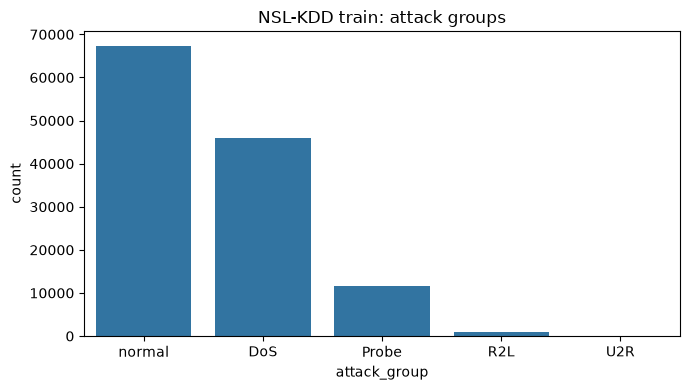

In [16]:
plt.figure(figsize=(7, 4))
order = nsl_train["attack_group"].value_counts().index
sns.countplot(data=nsl_train, x="attack_group", order=order)
plt.title("NSL-KDD train: attack groups")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "nslkdd_attack_groups.png"), dpi=150)
plt.show()

In [17]:
categorical_cols = nsl_train.select_dtypes(include="object").columns.tolist()
print("Categorical columns:", categorical_cols)
print("Columns to drop later: difficulty")

Categorical columns: ['protocol_type', 'service', 'flag', 'label', 'attack_group']
Columns to drop later: difficulty


C:\Users\Admin\AppData\Local\Temp\ipykernel_5592\78728800.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = nsl_train.select_dtypes(include="object").columns.tolist()


## Summary for data_notes.md

In [18]:
print("==== NSL-KDD summary ====")
print("Rows (train / test):", nsl_train.shape[0], "/", nsl_test.shape[0])
print("Columns            :", nsl_train.shape[1])
print("Missing values     :", nsl_train.isnull().sum().sum())
print("Duplicates (train) :", nsl_train.duplicated().sum())
print("Groups             :", nsl_train["attack_group"].unique().tolist())
print("Most common group  :", nsl_train["attack_group"].value_counts().idxmax())
print("Categorical columns:", categorical_cols)

==== NSL-KDD summary ====
Rows (train / test): 125973 / 22544
Columns            : 44
Missing values     : 0
Duplicates (train) : 0
Groups             : ['normal', 'DoS', 'R2L', 'Probe', 'U2R']
Most common group  : normal
Categorical columns: ['protocol_type', 'service', 'flag', 'label', 'attack_group']
